In [1]:
import hashlib
# Lets this notebook import our shared functions from the src/ folder
import sys
sys.path.append('..')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

SEED = 42
DATA = '../data/'
FIG = '../figures/'

In [2]:
ratings = pd.read_csv(
    DATA + 'ratings.csv',
    usecols=['userId', 'movieId', 'rating'],
    dtype={'userId': 'int32', 'movieId': 'int32', 'rating': 'float32'}
)
movies = pd.read_csv(DATA + 'movies.csv')

print('Ratings:', ratings.shape)
print('Movies:', movies.shape)
ratings.head()

Ratings: (32000204, 3)
Movies: (87585, 3)


,userId,movieId,rating
0,1,17,4.0
1,1,25,1.0
2,1,29,2.0
3,1,30,5.0
4,1,32,5.0


In [3]:
movies.head()

,movieId,title,genres
0,1,Toy Story (1995),Adventure|Animation|Children|Comedy|Fantasy
1,2,Jumanji (1995),Adventure|Children|Fantasy
2,3,Grumpier Old Men (1995),Comedy|Romance
3,4,Waiting to Exhale (1995),Comedy|Drama|Romance
4,5,Father of the Bride Part II (1995),Comedy


In [4]:
print('Number of users:', ratings['userId'].nunique())
print('Number of movies that were rated:', ratings['movieId'].nunique())
print('Number of movies in movies.csv:', len(movies))
print()
print('Missing values in ratings:\n', ratings.isna().sum())
print('Missing values in movies:\n', movies.isna().sum())
print()
print('Duplicate user-movie pairs:', ratings.duplicated(['userId', 'movieId']).sum())
print('Fewest ratings by one user:', ratings.groupby('userId').size().min())

Number of users: 200948
Number of movies that were rated: 84432
Number of movies in movies.csv: 87585

Missing values in ratings:
 userId     0
movieId    0
rating     0
dtype: int64
Missing values in movies:
 movieId    0
title      0
genres     0
dtype: int64

Duplicate user-movie pairs: 0
Fewest ratings by one user: 20


In [5]:
genre_counts = movies['genres'].str.split('|').explode().value_counts()
genre_counts

genres
Drama                 34175
Comedy                23124
Thriller              11823
Romance               10369
Action                 9668
Documentary            9363
Horror                 8654
(no genres listed)     7080
Crime                  6976
Adventure              5402
Sci-Fi                 4907
Animation              4617
Children               4520
Mystery                4013
Fantasy                3851
War                    2325
Western                1696
Musical                1059
Film-Noir               353
IMAX                    195
Name: count, dtype: int64

In [6]:
# Turn the genre text into a list, e.g. "Action|Sci-Fi|IMAX" -> ["Action", "Sci-Fi", "IMAX"]
movies['genres'] = movies['genres'].str.split('|')

# Remove the IMAX and "(no genres listed)" labels, keep the real genres
drop_labels = {'IMAX', '(no genres listed)'}
movies['genres'] = movies['genres'].apply(lambda g: [x for x in g if x not in drop_labels])

# Movies left with no genres at all are removed
no_genre = movies['genres'].str.len() == 0
print('Movies removed (no genres):', no_genre.sum())
movies_clean = movies[~no_genre].reset_index(drop=True)

# Remove the ratings of those movies
before_ratings = len(ratings)
before_users = ratings['userId'].nunique()
ratings = ratings[ratings['movieId'].isin(movies_clean['movieId'])].reset_index(drop=True)

print('Ratings removed:', before_ratings - len(ratings),
f'({(before_ratings - len(ratings)) / before_ratings:.2%} of all ratings)')
print('Users removed:', before_users - ratings['userId'].nunique())
print('Fewest ratings by one user now:', ratings.groupby('userId').size().min())
print('Genres left:', sorted(movies_clean['genres'].explode().unique()))

Movies removed (no genres): 7081
Ratings removed: 55528 (0.17% of all ratings)
Users removed: 0
Fewest ratings by one user now: 18
Genres left: ['Action', 'Adventure', 'Animation', 'Children', 'Comedy', 'Crime', 'Documentary', 'Drama', 'Fantasy', 'Film-Noir', 'Horror', 'Musical', 'Mystery', 'Romance', 'Sci-Fi', 'Thriller', 'War', 'Western']


In [7]:
# 1. Genre table: one row per movie, one True/False column per genre
movies_onehot = movies_clean['genres'].str.join('|').str.get_dummies(sep='|').astype(bool)
movies_onehot.insert(0, 'movieId', movies_clean['movieId'])

# 2. Pick a random 5% of users (seed 42, so everyone gets the same sample)
rng = np.random.default_rng(SEED)
all_users = ratings['userId'].unique()
sample_users = rng.choice(all_users, size=int(0.05 * len(all_users)), replace=False)
sample = ratings[ratings['userId'].isin(sample_users)]

# 3. Save the three files
ratings.to_parquet(DATA + 'clean_ratings.parquet', index=False)
sample.to_parquet(DATA + 'sample_ratings.parquet', index=False)
movies_onehot.to_parquet(DATA + 'movies_clean.parquet', index=False)

print('Genre table:', movies_onehot.shape)
print('Clean ratings:', ratings.shape, '| users:', ratings['userId'].nunique())
print('Sample ratings:', sample.shape, '| users:', sample['userId'].nunique())

Genre table: (80504, 19)
Clean ratings: (31944676, 3) | users: 200948
Sample ratings: (1599232, 3) | users: 10047


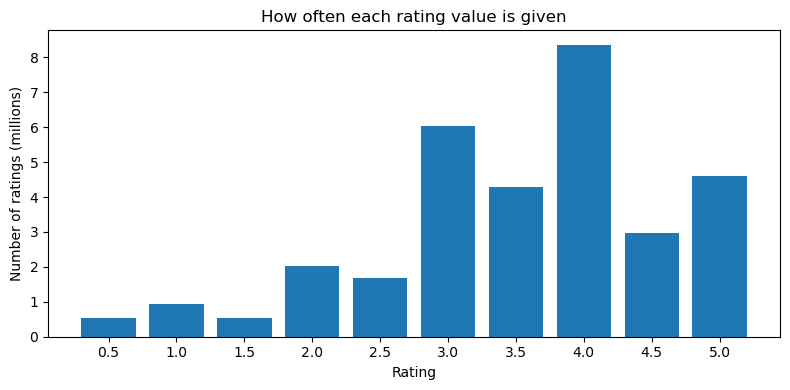

Share of ratings that count as liked (>= 4.0): 49.8%


In [8]:
counts = ratings['rating'].value_counts().sort_index()

plt.figure(figsize=(8, 4))
plt.bar(counts.index.astype(str), counts.values / 1e6)
plt.xlabel('Rating')
plt.ylabel('Number of ratings (millions)')
plt.title('How often each rating value is given')
plt.tight_layout()
plt.savefig(FIG + 'eda_rating_distribution.png', dpi=150)
plt.show()

liked_share = (ratings['rating'] >= 4.0).mean()
print(f'Share of ratings that count as liked (>= 4.0): {liked_share:.1%}')

Whole-star ratings are more common than half-star ones, and 4.0 is the most common rating. About half of all ratings are 4.0 or higher, so our “liked” rule (rating ≥ 4.0) splits the ratings roughly in half.

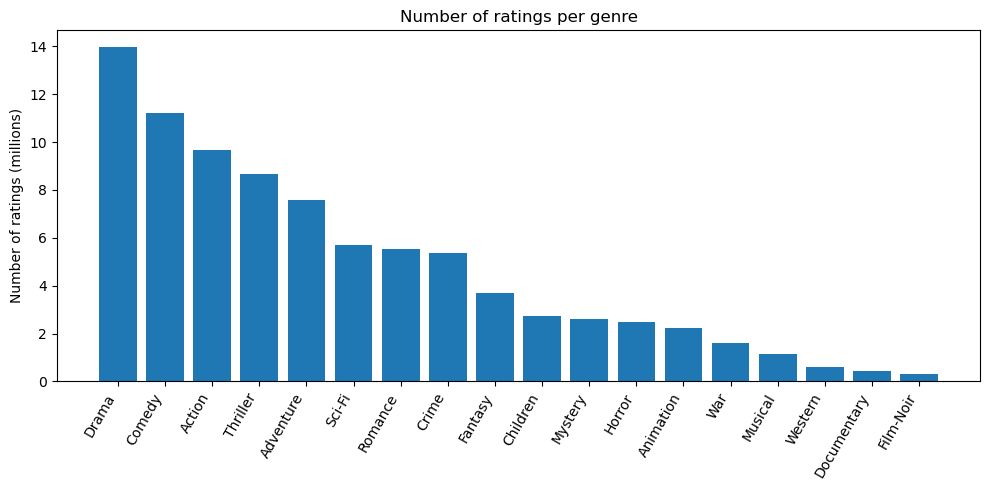

,ratings,likes,like_rate
Drama,13973271,7767984,0.556
Comedy,11206926,5087919,0.454
Action,9665213,4514423,0.467
Thriller,8679464,4242532,0.489
Adventure,7590522,3704655,0.488
Sci-Fi,5717337,2724764,0.477
Romance,5524615,2759311,0.499
Crime,5373051,3006682,0.560
Fantasy,3702759,1797234,0.485
Children,2731841,1251455,0.458


In [9]:
GENRES = [c for c in movies_onehot.columns if c != 'movieId']

# Count ratings and likes per movie first (small table), then spread over genres
per_movie = (ratings.assign(liked=ratings['rating'] >= 4.0)
             .groupby('movieId')
             .agg(n_ratings=('rating', 'size'), n_likes=('liked', 'sum'))
             .reset_index()
             .merge(movies_onehot, on='movieId'))

genre_stats = pd.DataFrame({
    'ratings': per_movie[GENRES].mul(per_movie['n_ratings'], axis=0).sum(),
    'likes':   per_movie[GENRES].mul(per_movie['n_likes'], axis=0).sum(),
})
genre_stats['like_rate'] = genre_stats['likes'] / genre_stats['ratings']
genre_stats = genre_stats.sort_values('ratings', ascending=False)

plt.figure(figsize=(10, 5))
plt.bar(genre_stats.index, genre_stats['ratings'] / 1e6)
plt.xticks(rotation=60, ha='right')
plt.ylabel('Number of ratings (millions)')
plt.title('Number of ratings per genre')
plt.tight_layout()
plt.savefig(FIG + 'eda_genre_popularity.png', dpi=150)
plt.show()

genre_stats.round(3)

Drama appears in about 44% of all ratings and Comedy in about 35%, so these genres will appear in many transactions. Rules ending in Drama may look strong only because Drama is popular, which is why we check lift. The most-rated genres are not the most liked: Film-Noir (67%) and War (61%) have the highest like rates, while Horror (41%) and Comedy (45%) have the lowest. Niche genres are probably watched mainly by people who already like them.

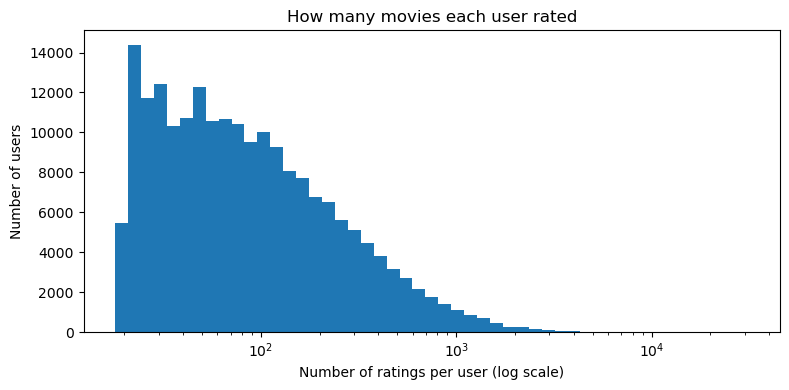

count    200948.0
mean        159.0
std         279.7
min          18.0
25%          36.0
50%          73.0
75%         166.0
max       31273.0
dtype: float64


In [10]:
per_user = ratings.groupby('userId').size()

plt.figure(figsize=(8, 4))
plt.hist(per_user, bins=np.logspace(np.log10(per_user.min()), np.log10(per_user.max()), 50))
plt.xscale('log')
plt.xlabel('Number of ratings per user (log scale)')
plt.ylabel('Number of users')
plt.title('How many movies each user rated')
plt.tight_layout()
plt.savefig(FIG + 'eda_ratings_per_user.png', dpi=150)
plt.show()

print(per_user.describe().round(1))

The median user rated 73 movies, but the mean is 159 and the maximum is 31,273, so a few very active users pull the average up. If we used raw counts per genre, the clusters would separate active users from casual users instead of different tastes. That is why the user profiles use the share of ratings in each genre, plus log(number of ratings) as one separate feature.